<div style="background:#0B2545;color:white;padding:18px 22px;border-radius:8px">
<div style="font-size:12px;letter-spacing:2px;opacity:.8">DATABANK ACADEMY · PROGRAMA EJECUTIVO EN GESTIÓN INTEGRAL DEL RIESGO DE CRÉDITO MINORISTA</div>
<div style="font-size:24px;font-weight:700;margin-top:6px">Módulo 5 · Sesión 1: CatBoost: variables categóricas, target statistics y ordered boosting</div>
<div style="font-size:14px;margin-top:4px;opacity:.9">Laboratorio: TS greedy, holdout, leave-one-out y ordenada desde cero; teorema 1 por simulación; Plain vs. Ordered; CatBoost vs. XGBoost</div>
</div>

## Objetivos de la sesión (2 horas)

Entender **por qué y cómo** CatBoost trata las variables categóricas y corrige el *prediction shift* del boosting, a partir del paper original: Prokhorenkova, Gusev, Vorobev, Dorogush y Gulin, *"CatBoost: unbiased boosting with categorical features"*, NeurIPS 2018 (arXiv:1706.09516).

1. El problema de las categóricas de **alta cardinalidad** en riesgo de crédito (agencia, empleador, comercio aliado).
2. **Target statistics (TS)**: greedy, holdout, leave-one-out y **ordered TS**; la fuga de información (*target leakage*) en cada una.
3. Implementar las cuatro TS **desde cero** y reproducir los ejemplos del paper (variable tipo ID y variable constante).
4. Efecto en un modelo real: XGBoost con TS greedy vs. K-fold vs. ordenadas.
5. **Prediction shift**: el teorema 1 del paper, verificado por simulación.
6. **Ordered boosting** (algoritmo 1) y su versión práctica; modos *Plain* y *Ordered* de CatBoost.
7. CatBoost en la cartera: combinaciones de categóricas, CTR y comparación con XGBoost.

| Bloque | Tiempo | Contenido |
|---|---|---|
| 1 | 10 min | Categóricas de alta cardinalidad |
| 2 | 30 min | Target statistics y fuga de información |
| 3 | 15 min | Efecto en un modelo de PD |
| 4 | 25 min | Prediction shift y ordered boosting |
| 5 | 30 min | CatBoost en la cartera |
| 6 | 10 min | Ejercicios |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
AZUL, ROJO, VERDE, GRIS, ORO = "#0B2545", "#C8102E", "#2E8B57", "#8D99AE", "#E0A100"
DATA = Path("../datos")

import time, xgboost as xgb, catboost
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import roc_auc_score, log_loss
from sklearn.model_selection import KFold
print("CatBoost", catboost.__version__, "| XGBoost", xgb.__version__)
app = pd.read_csv(DATA / "hc_application_sintetico.csv").drop_duplicates()
app["EDAD"] = -app.DAYS_BIRTH / 365.25
app["RCI"] = app.AMT_ANNUITY / (app.AMT_INCOME_TOTAL / 12)
app["ANTIG"] = np.where(app.DAYS_EMPLOYED == 365243, np.nan, -app.DAYS_EMPLOYED / 365.25)
app["PENSIONISTA"] = (app.DAYS_EMPLOYED == 365243).astype(int)
NUM = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "EDAD", "RCI", "ANTIG", "PENSIONISTA", "AMT_INCOME_TOTAL", "AMT_CREDIT",
       "AMT_REQ_CREDIT_BUREAU_YEAR", "REGION_RATING_CLIENT", "CNT_CHILDREN"]
ALTA = ["AGENCIA_ID", "EMPLEADOR_ID", "COMERCIO_ALIADO"]                       # alta cardinalidad
BAJA = ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "OCCUPATION_TYPE", "CODE_GENDER", "CANAL", "ORGANIZATION_TYPE"]
CAT = BAJA + ALTA
for c in CAT: app[c] = app[c].fillna("Sin dato").astype(str)
F = NUM + CAT
tr = app[app.FECHA_SOLICITUD < "2024-01"].reset_index(drop=True)                 # entrenamiento 2022-2023
va = app[(app.FECHA_SOLICITUD >= "2024-01") & (app.FECHA_SOLICITUD < "2025-01")].reset_index(drop=True)   # validación 2024
te = app[app.FECHA_SOLICITUD >= "2025-01"].reset_index(drop=True)                # prueba fuera de tiempo 2025
print(f"entrenamiento: {len(tr):,} | validación: {len(va):,} | prueba: {len(te):,}")

CatBoost 1.2.10 | XGBoost 3.4.1


entrenamiento: 30,039 | validación: 15,053 | prueba: 14,908


## 1. Categóricas de alta cardinalidad

En originación minorista abundan variables con cientos o miles de niveles: **agencia**, **empleador** (convenios de descuento por planilla), **comercio aliado** (crédito en punto de venta), distrito, actividad económica. Contienen información de riesgo real (un empleador con alta rotación, un comercio con fraude), pero:

- **One-hot** crea miles de columnas casi vacías; los árboles las aprovechan mal (cada partición aísla un nivel).
- **Codificación por etiquetas** (1, 2, 3…) impone un orden arbitrario.
- La mitad de los niveles tiene pocos clientes: la tasa de malos observada en ellos es casi puro ruido.

,niveles,clientes por nivel (mediana),% niveles con < 10 clientes,columnas one-hot
NAME_INCOME_TYPE,5,"5,389",0%,5
NAME_EDUCATION_TYPE,5,973,0%,5
OCCUPATION_TYPE,13,"1,149",0%,13
CODE_GENDER,3,"10,369",33%,3
CANAL,4,"6,436",0%,4
ORGANIZATION_TYPE,10,"1,372",0%,10
AGENCIA_ID,180,112,0%,180
EMPLEADOR_ID,"2,881",4,81%,"2,881"
COMERCIO_ALIADO,41,49,0%,41


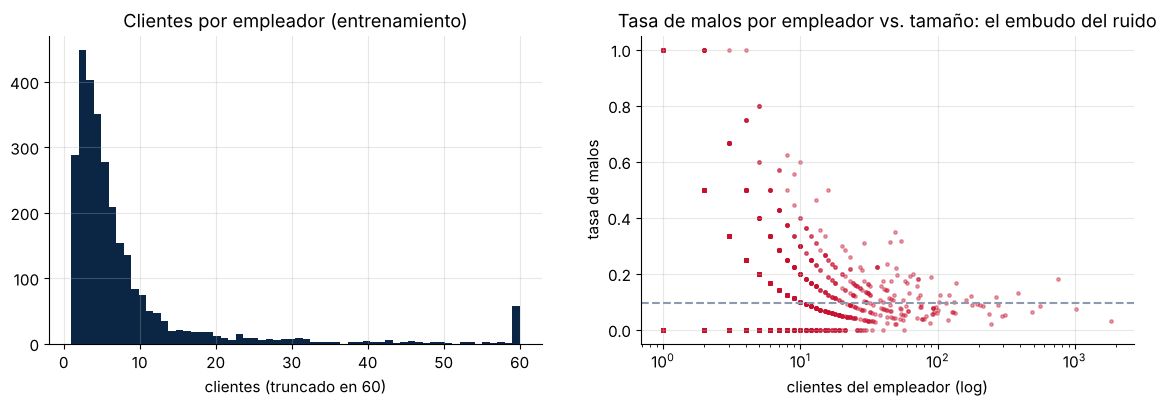

In [2]:
card = pd.DataFrame({c: {"niveles": tr[c].nunique(), "clientes por nivel (mediana)": tr[c].value_counts().median(),
                         "% niveles con < 10 clientes": (tr[c].value_counts() < 10).mean()} for c in CAT}).T
card["columnas one-hot"] = card["niveles"]
display(card.style.format({"niveles": "{:,.0f}", "clientes por nivel (mediana)": "{:,.0f}", "% niveles con < 10 clientes": "{:.0%}", "columnas one-hot": "{:,.0f}"}))
vc = tr.EMPLEADOR_ID.value_counts()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(vc.clip(upper=60), bins=60, color=AZUL); ax[0].set_title("Clientes por empleador (entrenamiento)"); ax[0].set_xlabel("clientes (truncado en 60)")
t = tr.groupby("EMPLEADOR_ID").TARGET.agg(["mean", "size"])
ax[1].scatter(t["size"], t["mean"], s=6, alpha=.4, color=ROJO); ax[1].set_xscale("log")
ax[1].axhline(tr.TARGET.mean(), color=GRIS, ls="--"); ax[1].set_title("Tasa de malos por empleador vs. tamaño: el embudo del ruido")
ax[1].set_xlabel("clientes del empleador (log)"); ax[1].set_ylabel("tasa de malos"); plt.show()

**Lectura:** el embudo muestra el problema: los empleadores pequeños tienen tasas de 0 % o 50 % por puro azar. Cualquier codificación basada en la tasa de malos debe **suavizar** hacia el promedio y, sobre todo, **no usar el propio target del cliente**.

## 2. Target statistics (Prokhorenkova et al., sección 3)

La idea: reemplazar la categoría $x^i_k$ del cliente $k$ por una estimación de $E[y \mid x^i = x^i_k]$. Con un **prior** $p$ (la tasa global) y un peso $a > 0$:

$$\hat x^i_k = \frac{\sum_{j \in \mathcal{D}_k} \mathbb{1}\{x^i_j = x^i_k\}\, y_j + a\,p}{\sum_{j \in \mathcal{D}_k} \mathbb{1}\{x^i_j = x^i_k\} + a}$$

Todo depende de **qué clientes** $\mathcal{D}_k$ se usan para calcular la estadística del cliente $k$:

| TS | $\mathcal{D}_k$ | Problema |
|---|---|---|
| **Greedy** | Todos los clientes, incluido $k$ | Fuga: $\hat x_k$ contiene $y_k$ |
| **Holdout** | Una parte de los datos reservada solo para calcular TS | Desperdicia datos |
| **Leave-one-out** | Todos menos $k$ | Fuga inversa: $\hat x_k$ depende de $y_k$ por exclusión |
| **Ordered** | Los clientes **anteriores** a $k$ en una permutación aleatoria $\sigma$ | Ninguno de los anteriores; varianza en los primeros casos |

El paper propone dos propiedades deseables: **P1** $E(\hat x^i \mid y = v) = E(\hat x^i_k \mid y_k = v)$ (la TS de entrenamiento se distribuye igual que la de prueba) y **P2** usar todos los datos. Solo la ordered TS cumple ambas.

### Implementación desde cero de las cuatro TS

In [3]:
y, yt = tr.TARGET.values, te.TARGET.values
p0, A = y.mean(), 1.0

def _stats(df, col):
    g = df.groupby(col).TARGET.agg(["sum", "count"]); return g["sum"], g["count"]

def _aplicar(s, n, serie):
    return np.array((serie.map(s).fillna(0) + A * p0) / (serie.map(n).fillna(0) + A), dtype=float)

def ts_greedy(col):
    s, n = _stats(tr, col); return _aplicar(s, n, tr[col]), _aplicar(s, n, te[col])

def ts_holdout(col, frac=0.5, seed=0):
    m = np.random.default_rng(seed).random(len(tr)) < frac              # m: casos reservados para calcular TS
    s, n = _stats(tr[m], col); x = _aplicar(s, n, tr[col]); x[m] = np.nan  # esos casos no se usan para entrenar
    return x, _aplicar(s, n, te[col])

def ts_loo(col):
    s, n = _stats(tr, col)
    x = np.array((tr[col].map(s) - tr.TARGET + A * p0) / (tr[col].map(n) - 1 + A), dtype=float)
    return x, _aplicar(s, n, te[col])

def ts_ordenada(col, seed=0):
    perm = np.random.default_rng(seed).permutation(len(tr)); xs, ys = tr[col].values[perm], y[perm]
    suma, cuenta, out = {}, {}, np.empty(len(tr))
    for i, (k, t) in enumerate(zip(xs, ys)):                           # solo usa los clientes anteriores en la permutación
        s_, n_ = suma.get(k, 0.0), cuenta.get(k, 0)
        out[i] = (s_ + A * p0) / (n_ + A); suma[k], cuenta[k] = s_ + t, n_ + 1
    x = np.empty(len(tr)); x[perm] = out
    s, n = _stats(tr, col); return x, _aplicar(s, n, te[col])            # en prueba: todos los datos de entrenamiento

def auc_seguro(yv, x):
    return roc_auc_score(yv, x) if np.nanstd(x) > 0 else 0.5

tr["ID_FALSO"], te["ID_FALSO"] = tr.SK_ID_CURR.astype(str), te.SK_ID_CURR.astype(str)   # un nivel por cliente (ejemplo del paper)
tr["CONSTANTE"], te["CONSTANTE"] = "A", "A"                                               # un solo nivel (ejemplo del paper)
filas = []
for col in ["ID_FALSO", "CONSTANTE", "EMPLEADOR_ID", "AGENCIA_ID", "COMERCIO_ALIADO"]:
    for nombre, f in [("greedy", ts_greedy), ("holdout", ts_holdout), ("leave-one-out", ts_loo), ("ordenada", ts_ordenada)]:
        x_tr, x_te = f(col); m = ~np.isnan(x_tr)
        filas.append({"variable": col, "TS": nombre, "AUC entrenamiento": auc_seguro(y[m], x_tr[m]), "AUC prueba 2025": auc_seguro(yt, x_te)})
res_ts = pd.DataFrame(filas).set_index(["variable", "TS"])
res_ts["brecha"] = res_ts["AUC entrenamiento"] - res_ts["AUC prueba 2025"]
display(res_ts.style.format("{:.3f}").background_gradient(subset=["brecha"], cmap="Reds", vmin=0, vmax=0.3))

**Lectura (los dos ejemplos del paper):**

- **ID_FALSO** (un nivel por cliente, sin información): con TS greedy, $\hat x_k = (y_k + ap)/(1 + a)$ separa perfectamente a buenos y malos en entrenamiento (**AUC = 1,000**); en prueba todos reciben el prior y el AUC es 0,5. Un árbol encontraría una partición "perfecta" que no generaliza.
- **CONSTANTE** (un solo nivel, sin información): con **leave-one-out**, $\hat x_k = (n^+ - y_k + ap)/(n - 1 + a)$ es *menor* para los malos que para los buenos: el AUC de entrenamiento es **0,000**, es decir, separación perfecta invertida. Es la fuga que el paper describe en la sección 3.2.
- **EMPLEADOR_ID**: la TS greedy promete AUC 0,80 en entrenamiento y entrega 0,59 en prueba. Holdout, LOO y ordenada tienen brechas pequeñas porque no usan el propio target. El AUC de prueba es el mismo para las cuatro (en prueba todas usan todo el entrenamiento): **la diferencia está en lo que el modelo aprende durante el entrenamiento**.
- **COMERCIO_ALIADO**: el nivel "Sin dato" agrupa a la mayoría de los clientes y se comporta como la variable constante del paper: la TS leave-one-out da un AUC de entrenamiento de 0,16 (separación invertida) sin ninguna información real.

## 3. Efecto en un modelo de PD: XGBoost con distintas TS

La prueba relevante no es el AUC de la variable sola, sino lo que pasa cuando un modelo de boosting la usa junto con las demás. Codificamos las tres variables de alta cardinalidad con TS greedy, con TS por **K-fold** (la práctica habitual, equivalente a varios holdouts) y con TS **ordenada**, y entrenamos el mismo XGBoost.

In [4]:
A = 10.0                                         # suavizado más fuerte para el modelo
def ts_kfold(col, k=5):
    x = np.zeros(len(tr))
    for f_, h_ in KFold(k, shuffle=True, random_state=0).split(tr):
        s, n = _stats(tr.iloc[f_], col); x[h_] = _aplicar(s, n, tr[col].iloc[h_])
    s, n = _stats(tr, col); return x, _aplicar(s, n, va[col]), _aplicar(s, n, te[col])

def con_valid(f):
    def g(col):
        x_tr, _ = f(col); s, n = _stats(tr, col); return x_tr, _aplicar(s, n, va[col]), _aplicar(s, n, te[col])
    return g

def matriz(d, enc, k):
    X = d[NUM].copy()
    for c in BAJA: X[c] = pd.Categorical(d[c], categories=sorted(app[c].unique()))
    for j, c in enumerate(ALTA): X[c + "_TS"] = enc[j][k]
    return X

filas = []
for nombre, f in [("greedy", con_valid(ts_greedy)), ("K-fold (5)", ts_kfold), ("ordenada", con_valid(ts_ordenada))]:
    enc = [f(c) for c in ALTA]; Xs = [matriz(d, enc, k) for k, d in enumerate([tr, va, te])]
    m = xgb.XGBClassifier(n_estimators=3000, learning_rate=0.03, max_depth=4, min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
                          early_stopping_rounds=100, eval_metric="logloss", enable_categorical=True).fit(Xs[0], tr.TARGET, eval_set=[(Xs[1], va.TARGET)], verbose=False)
    a_ = [roc_auc_score(d.TARGET, m.predict_proba(X)[:, 1]) for d, X in zip([tr, va, te], Xs)]
    filas.append({"TS": nombre, "árboles": m.best_iteration, "AUC entrenamiento": a_[0], "AUC validación 2024": a_[1], "AUC prueba 2025": a_[2]})
res_xgb_ts = pd.DataFrame(filas).set_index("TS")
display(res_xgb_ts.style.format({"árboles": "{:.0f}", "AUC entrenamiento": "{:.4f}", "AUC validación 2024": "{:.4f}", "AUC prueba 2025": "{:.4f}"}))

,árboles,AUC entrenamiento,AUC validación 2024,AUC prueba 2025
TS,,,,
greedy,159,0.8931,0.7541,0.7638
K-fold (5),344,0.8535,0.7897,0.7985
ordenada,401,0.8563,0.7904,0.7980


**Lectura:** con TS greedy el modelo se apoya en una variable que "conoce" el target en entrenamiento: AUC de entrenamiento altísimo, early stopping temprano y **3,5 puntos menos** de AUC fuera de tiempo. Con K-fold u ordenada el resultado es prácticamente el mismo y muy superior. Es la versión en crédito de la tabla 4 del paper:

| Dataset (paper) | Greedy | Holdout | Leave-one-out |
|---|---|---|---|
| Adult | +1,1 % | +2,1 % | +5,5 % |
| Amazon | **+40 %** | +8,3 % | +4,5 % |
| Internet | +33 % | +2,6 % | **+27 %** |
| Upselling | **+57 %** | +1,6 % | +3,9 % |
| Kick | +22 % | +1,3 % | +3,7 % |

*Aumento relativo del log-loss frente a la ordered TS (Prokhorenkova et al., tabla 4, extracto).* La ordered TS gana en todos los datasets; greedy es la peor opción casi siempre.

## 4. Prediction shift y ordered boosting (sección 4)

El mismo problema aparece **dentro del boosting**, aunque no haya categóricas. En la iteración $t$, el residuo del cliente $k$ se calcula con $F^{t-1}$, que fue entrenado **usando a $k$**. Por eso la distribución de $F^{t-1}(x_k) \mid x_k$ en entrenamiento difiere de la de un cliente nuevo: el gradiente está sesgado y el modelo final también. El paper lo llama **prediction shift**.

**Teorema 1** (versión simplificada): con $y = c_1 x^1 + c_2 x^2$, $x^1, x^2 \sim$ Bernoulli(½) independientes, pérdida cuadrática y dos *stumps*:
1. Si cada stump se entrena con una muestra **independiente** de tamaño $n$, el modelo es insesgado (salvo un término exponencialmente pequeño).
2. Si ambos usan la **misma** muestra, $E[F(x)] = f^*(x) - \frac{c_2}{n-1}\left(x^2 - \tfrac{1}{2}\right) + O(2^{-n})$.

Lo verificamos por simulación.

In [5]:
rng = np.random.default_rng(0); c1, c2, n, R = 2.0, 1.0, 15, 40000

def stump(X, r):                                   # mejor partición sobre una de las dos variables binarias
    mejor = None
    for j in range(2):
        m = X[:, j] == 1
        if m.all() or (~m).all(): continue
        v1, v0 = r[m].mean(), r[~m].mean(); sse = ((r - np.where(m, v1, v0)) ** 2).sum()
        if mejor is None or sse < mejor[0]: mejor = (sse, j, v0, v1)
    return mejor

pred = lambda Z, s: np.where(Z[:, s[1]] == 1, s[3], s[2])
grid = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]); acum = {"misma muestra": np.zeros(4), "muestras independientes": np.zeros(4)}; cuenta = 0
for _ in range(R):
    X = rng.integers(0, 2, (n, 2)); yv = c1 * X[:, 0] + c2 * X[:, 1]
    X2 = rng.integers(0, 2, (n, 2)); y2 = c1 * X2[:, 0] + c2 * X2[:, 1]
    s1 = stump(X, yv)
    if s1 is None: continue
    s2, s2b = stump(X, yv - pred(X, s1)), stump(X2, y2 - pred(X2, s1))
    if s2 is None or s2b is None: continue
    acum["misma muestra"] += pred(grid, s1) + pred(grid, s2); acum["muestras independientes"] += pred(grid, s1) + pred(grid, s2b); cuenta += 1
verdad = c1 * grid[:, 0] + c2 * grid[:, 1]
sesgo = pd.DataFrame({k: v / cuenta - verdad for k, v in acum.items()}, index=["x=(0,0)", "x=(0,1)", "x=(1,0)", "x=(1,1)"])
sesgo["teorema 1: −c₂(x²−½)/(n−1)"] = -c2 * (grid[:, 1] - 0.5) / (n - 1)
print(f"Sesgo del modelo E[F(x)] − f*(x), n = {n}, {cuenta:,} réplicas")
sesgo

Sesgo del modelo E[F(x)] − f*(x), n = 15, 40,000 réplicas


,misma muestra,muestras independientes,teorema 1: −c₂(x²−½)/(n−1)
"x=(0,0)",0.0364,0.0011,0.0357
"x=(0,1)",-0.0346,0.0008,-0.0357
"x=(1,0)",0.0346,-0.0006,0.0357
"x=(1,1)",-0.0364,-0.0009,-0.0357


**Lectura:** reutilizar los mismos datos para calcular los residuos y ajustar el siguiente árbol produce exactamente el sesgo que predice el teorema (±0,036 con $n = 15$); con muestras independientes el sesgo desaparece. El sesgo cae como $1/n$: importa más en **muestras pequeñas** (segmentos nuevos, productos recién lanzados, carteras de nicho).

### Algoritmo 1: ordered boosting
La solución es la misma idea de la ordered TS: el residuo del cliente $\sigma(j)$ se calcula con un modelo $M_{j-1}$ entrenado **solo con los clientes anteriores** en la permutación.

1. Generar una permutación aleatoria $\sigma$ de los $n$ clientes.
2. Mantener $n$ modelos de soporte $M_1, \dots, M_n$; $M_i$ se entrena con los primeros $i$ clientes.
3. En cada iteración, el residuo de $\sigma(j)$ es $r_j = y_j - M_{j-1}(x_j)$: un modelo que **nunca vio** a ese cliente.
4. Ajustar el árbol con esos residuos insesgados y actualizar los modelos de soporte.

Mantener $n$ modelos es inviable; CatBoost usa una aproximación: modelos de soporte solo en prefijos de tamaño $2^j$ ($O(\log n)$ modelos), **varias permutaciones** (una para cada árbol) y la **misma** permutación para las TS y para el boosting, de modo que ambos usan solo "el pasado". En la librería es `boosting_type="Ordered"`; el modo `"Plain"` es el boosting estándar (con ordered TS para las categóricas).

El paper (tabla 3) muestra que el modo Ordered ayuda sobre todo en datasets pequeños. Lo comprobamos con muestras de 2 000 clientes:

In [6]:
filas = []
for s in range(5):
    sub = tr.sample(2000, random_state=s)
    for bt in ["Plain", "Ordered"]:
        m = CatBoostClassifier(iterations=2000, learning_rate=0.03, depth=6, od_type="Iter", od_wait=100, boosting_type=bt, verbose=0, random_seed=s, allow_writing_files=False)
        m.fit(Pool(sub[F], sub.TARGET, cat_features=CAT), eval_set=Pool(va[F], va.TARGET, cat_features=CAT), use_best_model=True)
        p = m.predict_proba(te[F])[:, 1]; filas.append({"muestra": s, "modo": bt, "AUC 2025": roc_auc_score(yt, p), "log-loss 2025": log_loss(yt, p)})
peq = pd.DataFrame(filas).pivot(index="muestra", columns="modo", values=["AUC 2025", "log-loss 2025"])
peq.loc["promedio"] = peq.mean()
display(peq.style.format("{:.4f}"))

**Lectura:** con 2 000 clientes el modo Ordered mejora el AUC en 3 de las 5 muestras (+0,15 pp en promedio) con un log-loss prácticamente igual: una ganancia pequeña, del mismo orden que la tabla 3 del paper (entre −0,6 % y +3,9 % de log-loss según el dataset). Con la cartera completa la diferencia desaparece, y el modo Ordered es más lento.

## 5. CatBoost en la cartera completa

Además de las ordered TS, CatBoost:
- calcula varias **CTR** (*counter / target statistics*) por categórica: `Borders` (tasa de malos con prior), `Counter` (frecuencia del nivel), entre otras (`simple_ctr`);
- construye **combinaciones de categóricas** de forma codiciosa: al crecer el árbol combina las categóricas ya usadas con las nuevas (p. ej. agencia × canal), con sus propias TS (`max_ctr_complexity`);
- usa **varias permutaciones** para que las TS de los primeros clientes no tengan demasiada varianza;
- aplica **one-hot** solo a las categóricas con pocos niveles (`one_hot_max_size`).

In [7]:
modelos, filas = {}, []
for bt in ["Plain", "Ordered"]:
    t0 = time.time()
    m = CatBoostClassifier(iterations=3000, learning_rate=0.05, depth=6, eval_metric="Logloss", od_type="Iter", od_wait=150,
                           boosting_type=bt, verbose=0, random_seed=0, allow_writing_files=False)
    m.fit(Pool(tr[F], tr.TARGET, cat_features=CAT), eval_set=Pool(va[F], va.TARGET, cat_features=CAT), use_best_model=True)
    p = m.predict_proba(te[F])[:, 1]; modelos[bt] = m
    filas.append({"modelo": f"CatBoost ({bt})", "árboles": m.get_best_iteration(), "AUC 2025": roc_auc_score(yt, p), "log-loss 2025": log_loss(yt, p), "segundos": time.time() - t0})

def xcat(d, cols):
    return d[NUM + cols].assign(**{c: pd.Categorical(d[c], categories=sorted(app[c].unique())) for c in cols})
for nombre, cols in [("XGBoost categóricas nativas (todas)", CAT), ("XGBoost sin EMPLEADOR_ID", [c for c in CAT if c != "EMPLEADOR_ID"])]:
    t0 = time.time()
    mx = xgb.XGBClassifier(n_estimators=3000, learning_rate=0.03, max_depth=4, min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
                           early_stopping_rounds=100, eval_metric="logloss", enable_categorical=True).fit(xcat(tr, cols), tr.TARGET, eval_set=[(xcat(va, cols), va.TARGET)], verbose=False)
    p = mx.predict_proba(xcat(te, cols))[:, 1]
    filas.append({"modelo": nombre, "árboles": mx.best_iteration, "AUC 2025": roc_auc_score(yt, p), "log-loss 2025": log_loss(yt, p), "segundos": time.time() - t0})
r = res_xgb_ts.loc["ordenada"]
filas.append({"modelo": "XGBoost + TS ordenada (sección 3)", "árboles": r["árboles"], "AUC 2025": r["AUC prueba 2025"], "log-loss 2025": np.nan, "segundos": np.nan})
comp = pd.DataFrame(filas).set_index("modelo")
display(comp.style.format({"árboles": "{:.0f}", "AUC 2025": "{:.4f}", "log-loss 2025": "{:.4f}", "segundos": "{:.1f}"}, na_rep="—"))

,árboles,AUC 2025,log-loss 2025,segundos
modelo,,,,
CatBoost (Plain),494,0.7950,0.1909,24.4
CatBoost (Ordered),378,0.7925,0.1913,33.5
XGBoost categóricas nativas (todas),187,0.7751,0.1961,2.6
XGBoost sin EMPLEADOR_ID,258,0.7719,0.1970,2.5
XGBoost + TS ordenada (sección 3),401,0.7980,—,—


**Lectura:**
- CatBoost con las categóricas en bruto supera a XGBoost con categóricas nativas por casi 2 puntos de AUC, sin preprocesamiento. El tratamiento nativo de XGBoost particiona por subconjuntos de categorías y sobreajusta con 3 000 empleadores; quitar EMPLEADOR_ID solo le resta 0,3 puntos: **no logra extraer su información**.
- Pero **XGBoost con TS ordenada** alcanza a CatBoost (incluso lo supera ligeramente, 0,798 vs. 0,795): la ventaja no es "magia" del algoritmo, sino un **tratamiento correcto de las categóricas**. CatBoost la ofrece por defecto, sin riesgo de fuga y sin código adicional; con otras librerías hay que implementarla (y es fácil hacerlo mal, como mostró la TS greedy).
- Los modos Plain y Ordered dan resultados equivalentes con 30 000 clientes; Ordered tarda más.

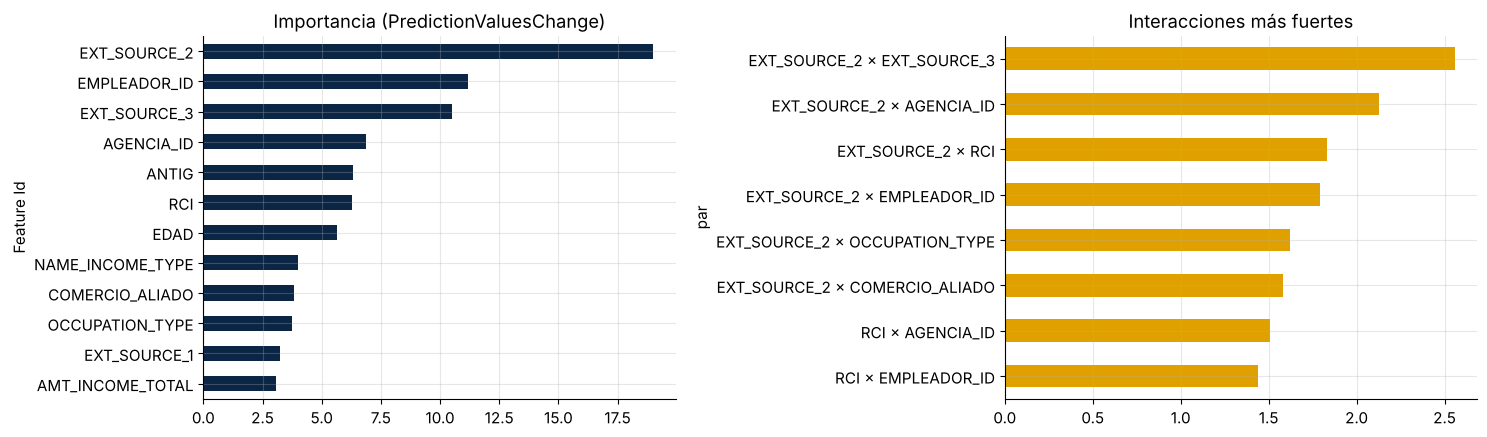

simple_ctr: ['Borders:CtrBorderCount=15:CtrBorderType=Uniform:TargetBorderCount=1:TargetBorderType=MinEntropy:Prior=0/1:Prior=0.5/1:Prior=1/1', 'Counter:CtrBorderCount=15:CtrBorderType=Uniform:Prior=0/1']
combinations_ctr: ['Borders:CtrBorderCount=15:CtrBorderType=Uniform:TargetBorderCount=1:TargetBorderType=MinEntropy:Prior=0/1:Prior=0.5/1:Prior=1/1', 'Counter:CtrBorderCount=15:CtrBorderType=Uniform:Prior=0/1']
max_ctr_complexity: 4 | one_hot_max_size: 2 | permutation_count: 4


In [8]:
m = modelos["Plain"]
imp = m.get_feature_importance(prettified=True).set_index("Feature Id")["Importances"].head(12)
inter = m.get_feature_importance(type="Interaction", prettified=True).head(8)
inter["par"] = [f"{F[int(a)]} × {F[int(b)]}" for a, b in zip(inter["First Feature Index"], inter["Second Feature Index"])]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
imp[::-1].plot.barh(ax=ax[0], color=AZUL); ax[0].set_title("Importancia (PredictionValuesChange)")
inter.set_index("par")["Interaction"][::-1].plot.barh(ax=ax[1], color=ORO); ax[1].set_title("Interacciones más fuertes")
plt.tight_layout(); plt.show()
pr = m.get_all_params()
print("simple_ctr:", pr.get("simple_ctr")); print("combinations_ctr:", pr.get("combinations_ctr"))
print("max_ctr_complexity:", pr.get("max_ctr_complexity"), "| one_hot_max_size:", pr.get("one_hot_max_size"), "| permutation_count:", pr.get("permutation_count"))

**Lectura:** EMPLEADOR_ID pasa a ser una de las variables más importantes, algo que ningún otro tratamiento logró sin trabajo adicional. Los parámetros muestran las CTR usadas por defecto (`Borders` y `Counter`) y la complejidad máxima de las combinaciones.

**Cuidado en riesgo de crédito:** una TS de empleador o de agencia es una variable que **cambia con el tiempo** (un empleador puede deteriorarse). En producción, la tabla de TS se recalcula con cada reentrenamiento y su estabilidad (PSI) se monitorea como la de cualquier variable (Módulo 12). También conviene revisar la equidad: una agencia puede actuar como proxy de una zona geográfica.

## 6. Ejercicios
1. Repite la tabla de la sección 2 con $a = 0$ (sin prior). ¿Qué TS empeora más? ¿Por qué el prior es imprescindible en niveles pequeños?
2. Implementa una TS ordenada con **varias permutaciones** (promediando 4) y compara su varianza en los primeros 1 000 clientes de la permutación.
3. Cambia `n` en la simulación del teorema 1 (5, 15, 50, 200) y grafica el sesgo contra $1/(n-1)$.
4. Entrena CatBoost con `one_hot_max_size=255`. ¿Qué pasa con AGENCIA_ID (180 niveles) y con el AUC?
5. Agrega `COMERCIO_ALIADO × CANAL` como variable explícita en XGBoost con TS ordenada. ¿Recupera la ventaja de las combinaciones de CatBoost?